# 04 — Explicabilité avec Grad-CAM

**Grad-CAM** (Selvaraju et al., ICCV 2017) répond à la question : *quelles zones de l'image ont fait
monter le score de la classe prédite ?* On prend les cartes d'activation de la dernière couche
convolutive du DenseNet-121 (`features.norm5`, 7×7×1024), on les pondère par la moyenne de leur
gradient, on somme et on garde la partie positive. La carte 7×7 est agrandie à 224×224.

Bibliothèque : `pytorch-grad-cam` (J. Gildenblat). On explique toujours **la classe prédite** au seuil
0,5 : la carte montre ce qui a poussé le modèle vers sa décision.

**Attention** : une carte Grad-CAM est une *indication* grossière (résolution 7×7), pas une preuve.
Elle sert ici à détecter des comportements suspects, notamment l'**apprentissage de raccourcis**
(*shortcut learning*, cf. Zech et al., PLOS Medicine 2018) : le modèle s'appuie-t-il sur les poumons,
ou sur des éléments parasites (bords de l'image, lettres, marqueurs, électrodes) ?

In [1]:
import sys
from pathlib import Path

# Le notebook est dans notebooks/ : on remonte à la racine du dépôt pour importer src/
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.precision", 3)
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"dpi": 90, "bbox_inches": "tight"}
import json, torch
from src.data import DOSSIER_FIGURES, DOSSIER_MODELES, DOSSIER_RESULTATS, charger_split_et_cache
from src.models import charger_modele
from src.gradcam import (cartes_gradcam, part_energie_bord, selectionner_cas, figure_cas,
                         figure_carte_moyenne, LIBELLES_CAS)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NOM, SEUIL = "densenet121", 0.5
df, cache = charger_split_et_cache()
pred = pd.read_csv(DOSSIER_RESULTATS / "predictions_test.csv")
modele = charger_modele(NOM, DOSSIER_MODELES / f"{NOM}_meilleur.pt", device)
images_test = cache[(df.split == "test").to_numpy()]
pred_classes = (pred[f"proba_{NOM}"] >= SEUIL).astype(int).to_numpy()
cartes = cartes_gradcam(modele, images_test, pred_classes)       # 624 cartes, classe prédite
np.save(DOSSIER_RESULTATS / f"cartes_gradcam_test_{NOM}.npy", cartes.astype(np.float16))
pred["part_bord"] = part_energie_bord(cartes)
print(cartes.shape)

(624, 224, 224)


## 1. Un cas de chaque type : VP, VN, FP, FN (les plus « sûrs d'eux »)

{'VP': ['person87_bacteria_434.jpeg'], 'VN': ['IM-0070-0001.jpeg'], 'FP': ['NORMAL2-IM-0256-0001.jpeg'], 'FN': ['person154_bacteria_728.jpeg']}


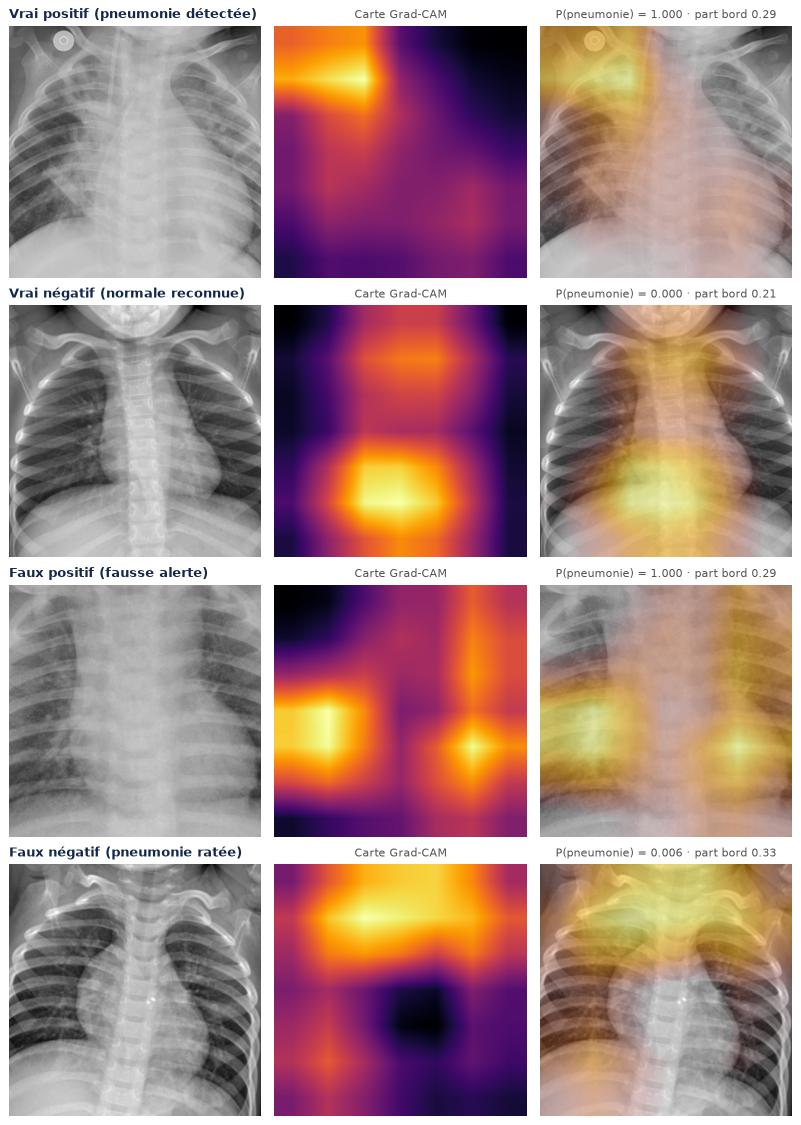

In [2]:
def lignes_pour(cas_par_type):
    lignes = []
    for cle, sel in cas_par_type.items():
        for i, r in sel.iterrows():
            lignes.append({"chemin": r.chemin, "carte": cartes[i], "titre": LIBELLES_CAS[cle],
                           "sous_titre": f"P(pneumonie) = {r[f'proba_{NOM}']:.3f} · part bord {r.part_bord:.2f}"})
    return lignes

cas = selectionner_cas(pred, NOM, SEUIL, n=1)
print({k: list(v.fichier) for k, v in cas.items()})
figure_cas(lignes_pour(cas), DOSSIER_FIGURES / "gradcam_4_cas.png");

### Lecture des 4 cas (avec prudence : je ne suis pas radiologue)
- **Vrai positif** (`person87_bacteria_434`, P = 1,000) : la zone chaude couvre le haut du poumon droit du patient (à gauche de l'image), où se trouve aussi un **objet rond (probablement une électrode)**. À la résolution de Grad-CAM (7×7), on ne peut pas dire si c'est l'opacité ou l'objet qui a compté.
- **Vrai négatif** (P = 0,000) : pour la classe « normale », la carte se concentre au centre (cœur, médiastin) et au cou, pas sur les champs pulmonaires. Grad-CAM montre où le modèle trouve des indices de « normalité », ce qui est plus difficile à interpréter.
- **Faux positif** (`NORMAL2-IM-0256`, P = 1,000) : l'image est globalement grise et peu contrastée, et la carte couvre les deux poumons. Hypothèse : ce voile, qui peut venir de l'exposition ou de la qualité de l'image, ressemble à des opacités pour le modèle.
- **Faux négatif** (`person154_bacteria_728`, P = 0,006) : pour un œil non médical, les poumons paraissent bien aérés, et la carte regarde le haut de l'image (clavicules, cou). Soit l'anomalie est subtile, soit l'étiquette est discutable : seul un radiologue pourrait trancher.

## 2. Les erreurs : 3 faux positifs et 3 faux négatifs

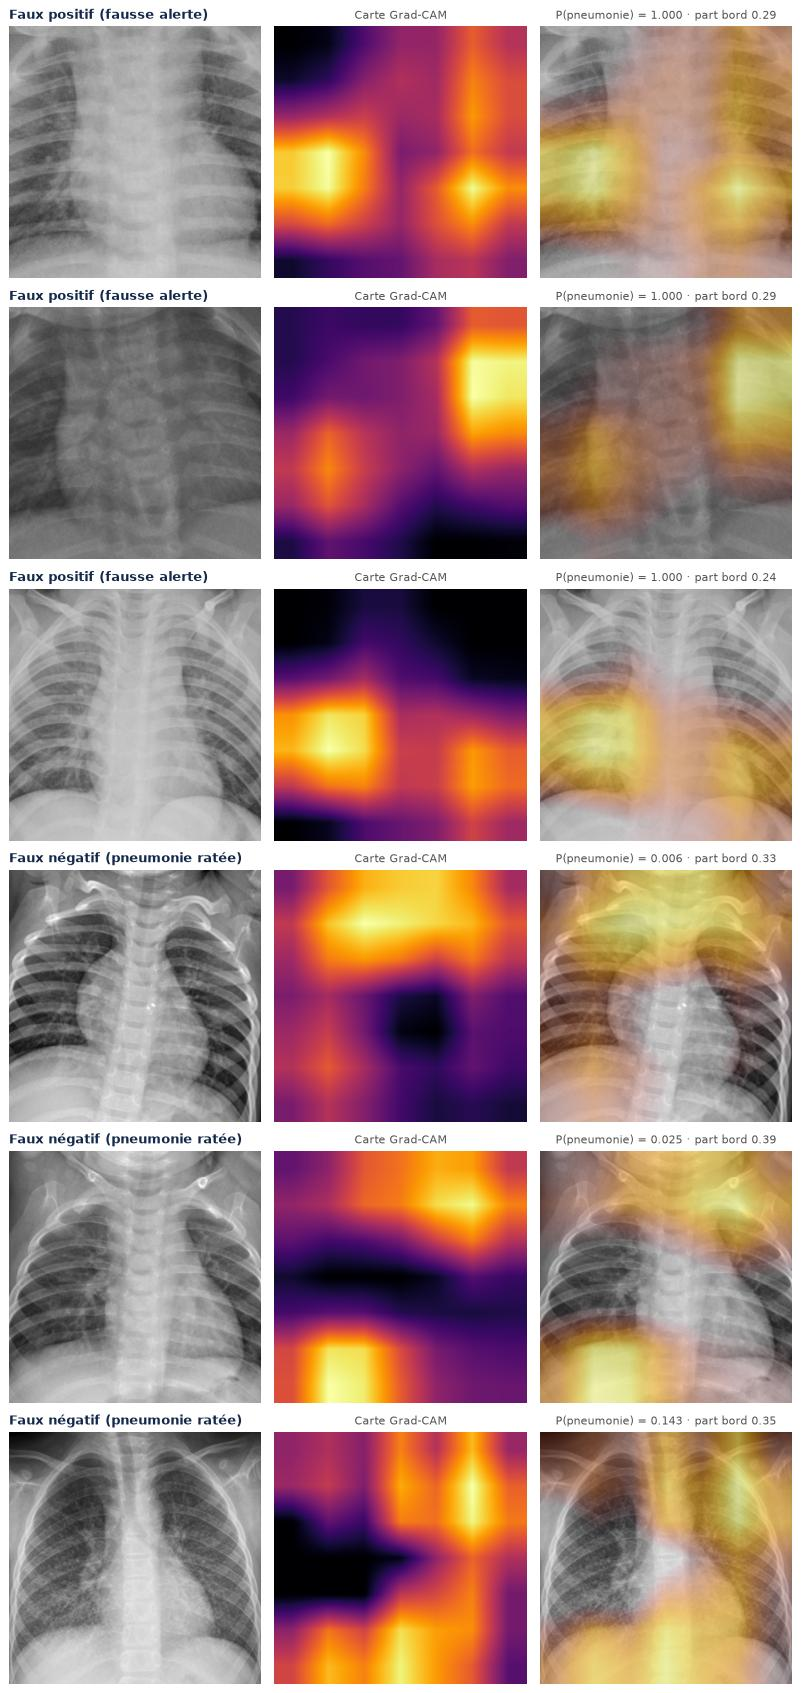

In [3]:
cas = selectionner_cas(pred, NOM, SEUIL, n=3)
figure_cas(lignes_pour({"FP": cas["FP"], "FN": cas["FN"]}), DOSSIER_FIGURES / "gradcam_erreurs.png");

### Observations sur les erreurs
- Les 3 faux positifs les plus « sûrs » (P ≈ 1,0) sont des radios normales de la série `NORMAL2-IM-02xx/03xx`, souvent grises et peu contrastées. Les cartes sont sur les poumons : le modèle « voit » quelque chose dans les champs pulmonaires, peut-être un effet de la qualité d'image.
- Les 3 faux négatifs (P de 0,006 à 0,143, et ce sont les seuls du test) ont des cartes tournées vers le haut de l'image ou le bas du thorax plutôt que vers les poumons. Leur part de bord moyenne est la plus élevée (0,355).

## 3. Vue d'ensemble : où regarde le modèle, en moyenne ?

On mesure pour chaque image la **part de la carte située dans la bande de bord** (les 10 % extérieurs
de chaque côté, soit 36 % de la surface). Une carte uniforme donnerait 0,36 ; une carte centrée sur
les poumons donne une valeur faible ; une valeur élevée signale un regard porté sur les bords.

In [4]:
stats = {
    "part_bord_moyenne": float(pred.part_bord.mean()),
    "part_bord_mediane": float(pred.part_bord.median()),
    "par_classe_predite": pred.groupby(pred_classes).part_bord.mean().rename({0: "NORMAL", 1: "PNEUMONIA"}).to_dict(),
    "par_type": pred.assign(t=np.select([(pred.label == 1) & (pred_classes == 1), (pred.label == 0) & (pred_classes == 0),
                                          (pred.label == 0) & (pred_classes == 1)], ["VP", "VN", "FP"], "FN"))
                    .groupby("t").part_bord.agg(["mean", "size"]).round(3).to_dict("index"),
    "n_cartes_majoritairement_bord(>0.5)": int((pred.part_bord > 0.5).sum()),
}
with open(DOSSIER_RESULTATS / f"gradcam_stats_{NOM}.json", "w", encoding="utf-8") as f:
    json.dump(stats, f, indent=2, ensure_ascii=False)
print(json.dumps(stats, indent=2, ensure_ascii=False))

{
  "part_bord_moyenne": 0.24727879464626312,
  "part_bord_mediane": 0.2402300238609314,
  "par_classe_predite": {
    "NORMAL": 0.2874199151992798,
    "PNEUMONIA": 0.229303777217865
  },
  "par_type": {
    "FN": {
      "mean": 0.35499998927116394,
      "size": 3
    },
    "FP": {
      "mean": 0.22200000286102295,
      "size": 44
    },
    "VN": {
      "mean": 0.28600001335144043,
      "size": 190
    },
    "VP": {
      "mean": 0.23000000417232513,
      "size": 387
    }
  },
  "n_cartes_majoritairement_bord(>0.5)": 2
}


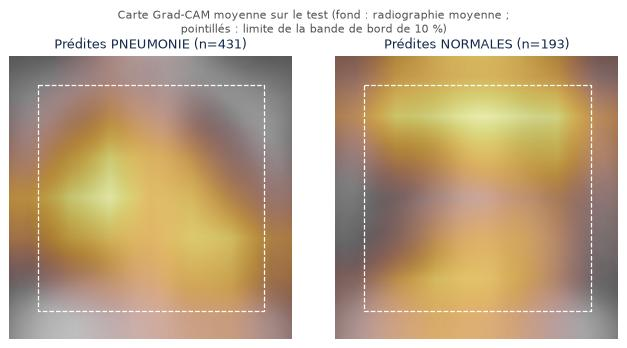

In [5]:
figure_carte_moyenne(cartes, pred_classes, images_test.mean(axis=0),
                     chemin=DOSSIER_FIGURES / "gradcam_carte_moyenne.png");

## 4. Les cartes les plus tournées vers les bords (recherche de raccourcis)

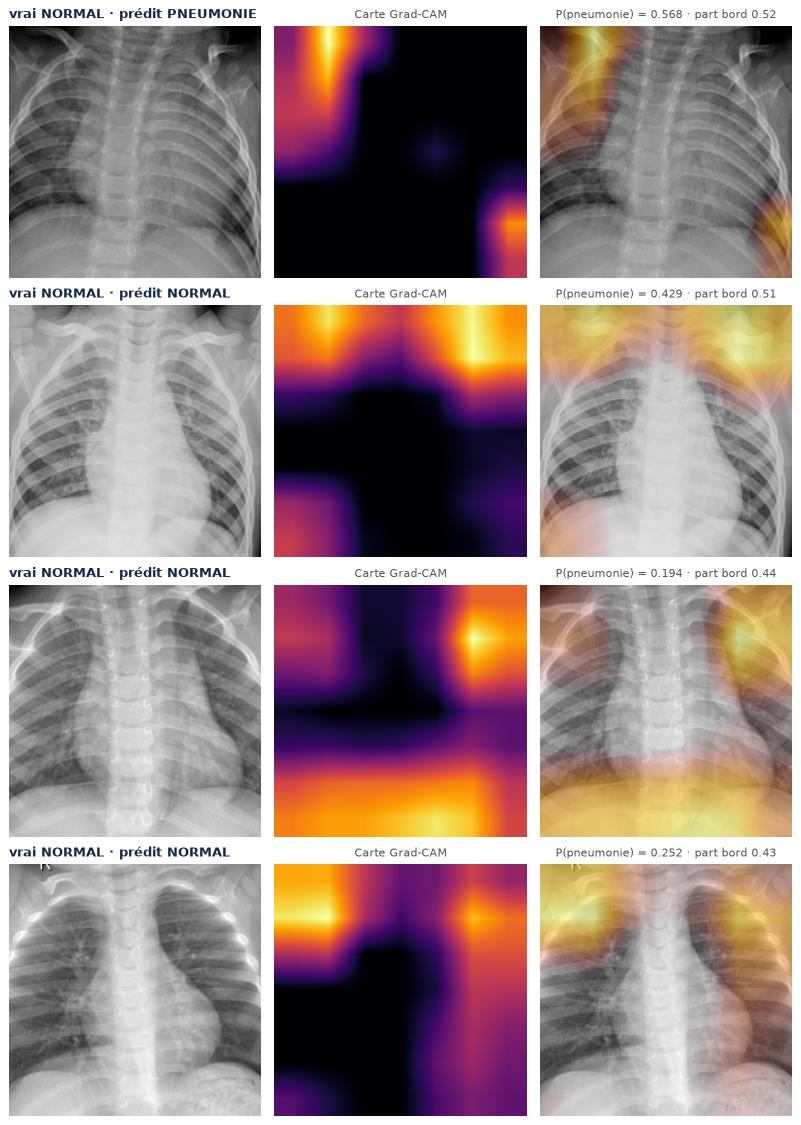

In [6]:
top = pred.sort_values("part_bord", ascending=False).head(4)
lignes = [{"chemin": r.chemin, "carte": cartes[i],
           "titre": f"vrai {'PNEUMONIE' if r.label else 'NORMAL'} · prédit {'PNEUMONIE' if pred_classes[i] else 'NORMAL'}",
           "sous_titre": f"P(pneumonie) = {r[f'proba_{NOM}']:.3f} · part bord {r.part_bord:.2f}"}
          for i, r in top.iterrows()]
figure_cas(lignes, DOSSIER_FIGURES / "gradcam_bords.png");

### Observations : y a-t-il des raccourcis ?
- En moyenne, **24,7 %** de la carte tombe dans la bande de bord, contre 36 % pour une carte uniforme : le modèle regarde **surtout le centre**. Seules **2 cartes sur 624** sont majoritairement sur les bords.
- Carte moyenne : pour les radios prédites **pneumonie**, les champs pulmonaires ; pour les **normales**, le haut du médiastin, le cou et la région du cœur.
- Les cartes les plus tournées vers les bords sont des cas **incertains** (P entre 0,19 et 0,57) : le modèle regarde alors les épaules, les coins supérieurs, et une fois la zone d'un marqueur « R ».
- **Conclusion honnête** : pas de signe d'un usage systématique des marqueurs ou des bords, mais Grad-CAM dit *où* le modèle regarde, pas *ce qu'il* y voit (texture, contraste, exposition). Le biais d'acquisition repéré dans le notebook 01 (forme des images) a été neutralisé géométriquement, mais d'autres différences d'acquisition peuvent subsister.

## 5. Grad-CAM vs Grad-CAM++ (même modèle, mêmes images)

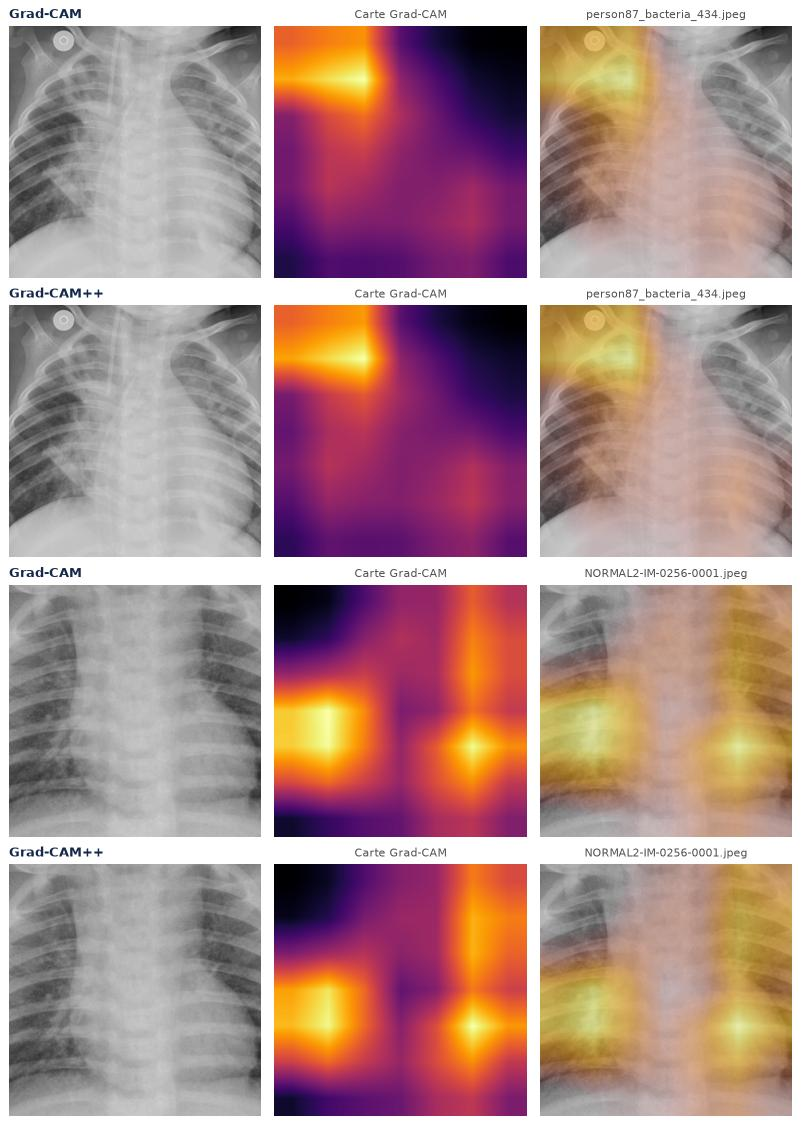

In [7]:
cas = selectionner_cas(pred, NOM, SEUIL, n=1)
idx = [cas["VP"].index[0], cas["FP"].index[0]]
pp = cartes_gradcam(modele, images_test[idx], pred_classes[idx], methode="gradcam++")
lignes = []
for k, i in enumerate(idx):
    r = pred.loc[i]
    lignes.append({"chemin": r.chemin, "carte": cartes[i], "titre": f"Grad-CAM", "sous_titre": r.fichier})
    lignes.append({"chemin": r.chemin, "carte": pp[k], "titre": f"Grad-CAM++", "sous_titre": r.fichier})
figure_cas(lignes, DOSSIER_FIGURES / "gradcam_vs_gradcampp.png");

### Conclusion
- Grad-CAM et Grad-CAM++ donnent ici des cartes **presque identiques** : le choix de la méthode change peu l'interprétation.
- Les cartes sont **grossières** (7×7 agrandies) : elles indiquent une région, pas une lésion. Ce n'est **pas une localisation validée**.
- Pour les pneumonies, le modèle regarde globalement les poumons, ce qui est rassurant. Mais deux points restent à creuser : des objets (électrodes) se trouvent parfois dans les zones chaudes, et les fausses alertes concernent des images peu contrastées.
- Pour aller plus loin, il faudrait des annotations de lésions par des radiologues, et un test sur des données d'un autre hôpital.